In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

True

### Tools


Models can request to call tools that perform tasks such as fetching data from a database, searching the web, or running code, . Tools are pairings of: 
1. A schema , including the name of the tool, a descrioption, and /or argument definitions
2. A function or coroutine to execute

In [3]:
import os
from langchain.chat_models import init_chat_model
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
model = init_chat_model("groq:openai/gpt-oss-20b")
response = model.invoke("Why do Parrot Talk?")
response.content


'### Why Do Parrots Talk?\n\nParrots are among the few non‑human animals that can produce and use human‑style speech. Their “talking” is the result of a unique blend of biology, cognition, and environment. Below is a quick‑look guide that breaks down the key factors:\n\n| Factor | How it Works | Why It Leads to Talking |\n|--------|--------------|-------------------------|\n| **Vocal‑learning brain** | Parrots possess a specialized “song system” in the brain—similar to the human Broca’s and Wernicke’s areas—that supports learning and reproducing sounds. | They can *memorize* and *reproduce* the exact pitch, rhythm, and timbre of human speech. |\n| **Syrinx (vocal organ)** | The syrinx is located at the base of the trachea and can produce a wide range of sounds, including rapid, complex consonant clusters that most birds can’t make. | Its flexibility lets parrots mimic the fine nuances of human voices. |\n| **Social nature** | In the wild, parrots live in tight, vocal groups where commu

To import tool we need to use tool library .
this is a way of creating agent using binding the tool

In [6]:
from langchain.tools import tool # langchain is a library , langchain.tools is a module, and tool is a function within that module.
@tool  # this is a decorator that marks the following function as a tool that can be used by the agent.
def get_weather(location: str)->str:
    """
    get the weather for a given location.
    """
    return f"it's sunny in {location}!"
## now my tool is ready to be used by the agent. This tool includes a function that takes a location as input , a description and returns a string indicating the weather in that location. The @tool decorator allows the agent to recognize this function as a tool that can be invoked when needed.
# now i need to bind the tool with my llm model
model_with_tools = model.bind_tools([get_weather])

# this is a way to bind the tool and create an agent that can use the tool when needed. The model_with_tools object is now an agent that can invoke the get_weather tool when it needs to get the weather for a given location.
# this is the most simpliest method to create an agent with tools.


now how  to call this model

In [7]:
response = model_with_tools.invoke("What is the weather like in New York?")
print(response)

tool_calls = response.tool_calls   

print(f"Tool: {tool_calls[0]['name']}")
print(f"Args: {tool_calls[0]['args']}")

content='' additional_kwargs={'reasoning_content': 'We need to call the get_weather function.', 'tool_calls': [{'id': 'fc_55a90415-7734-4ac0-acd3-8f638ef05fbe', 'function': {'arguments': '{"location":"New York"}', 'name': 'get_weather'}, 'type': 'function'}]} response_metadata={'token_usage': {'completion_tokens': 34, 'prompt_tokens': 130, 'total_tokens': 164, 'completion_time': 0.035396681, 'completion_tokens_details': {'reasoning_tokens': 10}, 'prompt_time': 0.006779718, 'prompt_tokens_details': None, 'queue_time': 0.367352546, 'total_time': 0.042176399}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_ce54c53bd5', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a1a8dd-7234-7401-88eb-f8762dfcaf1c-0' tool_calls=[{'name': 'get_weather', 'args': {'location': 'New York'}, 'id': 'fc_55a90415-7734-4ac0-acd3-8f638ef05fbe', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 130, 'outp

there is an another way of creating agent which is aforementioned in langchain intro file

In [11]:
from langchain.agents import create_agent
def get_weather(location: str)->str:
    """
    get the weather for a given location.
    """
    return f"it's sunny in {location}!"

agent = create_agent(
    model = "groq:openai/gpt-oss-20b",
    tools = [get_weather],
    system_prompt = "You are a helpful assistant that can provide weather information."
)

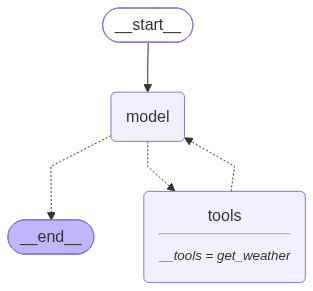

In [12]:
agent

In [43]:
### run the agent
# here we specified role as user and the content of the message as a dictionary
response = agent.invoke({"messages":[{"role":"user","content":"What is the weather like in New York?"}]})

response["messages"][2].content

"it's sunny in New York!"

## Tool execution loop

In [10]:
# step 1: Model generates tool calls
messages = [{"role":"user", "content":"Whats the weather in Boston?"}]
ai_msg = model_with_tools.invoke(messages)
messages.append(ai_msg)

#step2: Execute tools and collect results
for tool_call in ai_msg.tool_calls:
    tool_result =  get_weather.invoke(tool_call)
    messages.append(tool_result)

#step3: Pass results back to model for final response
final_response = model_with_tools.invoke(messages)
print(final_response.text)

It’s sunny in Boston!


In [ ]:
messages

[{'role': 'user', 'content': 'Whats the weather in Boston?'},
 AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to use the get_weather function.', 'tool_calls': [{'id': 'fc_97d8450c-7fcd-4830-a4f7-e66631d9ab3b', 'function': {'arguments': '{"location":"Boston"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 127, 'total_tokens': 160, 'completion_time': 0.045009625, 'completion_tokens_details': {'reasoning_tokens': 10}, 'prompt_time': 0.006239181, 'prompt_tokens_details': None, 'queue_time': 0.289025475, 'total_time': 0.051248806}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d3e146e1a5', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1a8de-c38e-702d-a7a3-6106821322cd-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Boston'}, 'id': 'fc_97d8450c-7fcd-4830-a4f7-e66631d9ab3b', 'type': 'tool_

: 